# Simulation of a Constant-Pressure Vented Batch Reactor (an index-2 DAE)

This tutorial uses `DAESLV`, the CRONOS solver built on [SUNDIALS IDAS](https://sundials.readthedocs.io/en/latest/idas/index.html). Where `ODESLV` integrates a
model's **divided** form -- every state needs an explicit derivative -- `DAESLV` integrates the
**undivided** form, a mass matrix and a residual. That is what lets it carry genuine
differential-algebraic systems, and this example is one of them.

A gas-phase reaction
$$\begin{equation*}
    {\sf A} \xrightarrow{k} 2{\sf B}
\end{equation*}$$
runs in a rigid, isothermal vessel. The reaction creates moles, so the pressure would rise; a vent
removes gas at a molar rate $q(t)$ chosen to hold the pressure **constant**. At fixed $T$ and $V$,
constant pressure means a constant total molar holdup $n^\ast = PV/RT$.

The model is
$$\begin{align*}
  \dot{n}_{\sf A}(t) &= -k\,n_{\sf A}(t) - q(t)\,x_{\sf A}(t) \\
  \dot{n}_{\sf B}(t) &= 2k\,n_{\sf A}(t) - q(t)\,x_{\sf B}(t) \\
           0 &= n_{\sf A}(t) + n_{\sf B}(t) - n_{T}
\end{align*}$$
with mole fractions $x_i = n_i/n_{T}$. The states are $n_{\sf A}$, $n_{\sf B}$ and the vent rate
$q$ -- and $q$ is what makes this interesting.

## Why this is index 2

The algebraic equation does not mention $q$ at all, so it cannot be solved for it. Differentiating
it once along the dynamics gives
$$\begin{equation*}
  \dot{n}_{\sf A} + \dot{n}_{\sf B} = k\,n_{\sf A}(t) - q(t) = 0 ,
\end{equation*}$$
which **does** determine $q = k\,n_{\sf A}$. One differentiation was needed to expose the algebraic
variable, so the DAE has differential index 2.

The practical consequence is that the initial state is not free. Supplying $n_{\sf A}(0)$ alone,
the solver must find $n_{\sf B}(0)$ from the constraint and $q(0)$ from its **hidden** derivative.
`DAESLV` does that automatically: index reduction is part of the model declaration, and consistent
initialisation solves the original rows together with the hidden ones.

## A closed form to check against

Substituting $q = k\,n_{\sf A}$ and $x_{\sf A} = n_{\sf A}/n_{T}$ into the first equation gives a
logistic ODE whose solution is
$$\begin{equation*}
  n_{\sf A}(t) = \frac{a\,e^{-kt}}{1 - a\,e^{-kt}/n_{T}} , \qquad
  a = \frac{n_{\sf A}(0)}{1 + n_{\sf A}(0)/n_{T}} ,
\end{equation*}$$
so every number below can be checked rather than merely inspected.

We import `pymcpp` and `cronos`.

In [1]:
import pymcpp
import cronos
from pymcpp import FFGraph, FFPartial, FFIntegral, FFEval
from cronos import FFDom, FFModel, DAESLV, FFDAESLV

## Declaring the model

The declaration is the same as any `FFModel`: an evolution domain, the states, the inputs, and the
equations with the region each holds on. The difference from an ODE model is that the equations are
written as they stand, without solving any of them for a derivative.

$n_T$ is fixed by the vessel and the operating pressure. The horizon is normalised to
$t \in [0,1]$ and split into 4 elements.

In [2]:
DAG           = FFGraph()
t             = DAG.add_var("t")
nA, nB, q     = DAG.add_var("nA"), DAG.add_var("nB"),  DAG.add_var("q")
k, nA0, nT    = DAG.add_var("k"),  DAG.add_var("nA0"), DAG.add_var("nT")
OpP, OpI, OpE = FFPartial(), FFIntegral(), FFEval()

IVP = DAESLV(DAG)
IVP.add_domain(t, FFDom(0., 1.))
IVP.set_evolution_domain(t)
IVP.add_state(nA, [t], ref=0.5)
IVP.add_state(nB, [t], ref=0.5)
IVP.add_state(q,  [t], ref=0.1)             # the ALGEBRAIC state: no derivative of its own
IVP.add_input(k)
IVP.add_input(nA0)
IVP.set_constant([nT])

IVP.add_equation(OpP(nA, t) + k*nA + q*nA/nT,    [t], [FFDom.ALL - FFDom.LB], FFModel.EqnRole.INTERIOR)
IVP.add_equation(OpP(nB, t) - 2.*k*nA + q*nB/nT, [t], [FFDom.ALL - FFDom.LB], FFModel.EqnRole.INTERIOR)
IVP.add_equation(nA + nB - nT,                   [t], [FFDom.ALL],            FFModel.EqnRole.INTERIOR)   # algebraic, everywhere
IVP.add_equation(nA - nA0,                       [t], [FFDom.LB],             FFModel.EqnRole.INITIAL)    # the ONLY IC supplied

IVP.add_output(OpE(nA, t, 1.))              # n_A at the end of the batch
IVP.add_output(OpI(q, t))                   # total vented moles, a quadrature

IVP.options.SOLVE.RTOL = IVP.options.SOLVE.ATOL = 1e-10
IVP.options.SOLVE.VERBOSE = 0
assert IVP.setup(), IVP.extract_error()

#print("states: %d   outputs: %d   parameters: %d" % (IVP.nx(), IVP.nf(), IVP.np()))
IVP.report()


  [maxthread] cap=1 via omp(was 16) openblas(was 16) + cholmod.nthreads_max; restored on exit


FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3


FFModel::setup ** high-index reduction: 1 hidden constraint level(s) materialised at the initial point (block 0); the model declares the free initial data only



FFModel ** the WORKING model (after setup)

DOMAINS (1)
  t              [0 : 1]  elements=1 nodes/element=4   <= EVOLUTION (set)

STATES (3)
  nA                   on t
  nB                   on t
  q                    on t

INPUTS (2)
  k                    on -
  nA0                  on -

CONSTANTS (1)
  nT                  

EQUATIONS (5)
  INTERIOR   block=0   0 = Partial[t]( nA ) + nA * k + ( nA * q ) / nT   on t in (0, 1]
  INTERIOR   block=0   0 = Partial[t]( nB ) - nA * k * 2 + ( nB * q ) / nT   on t in (0, 1]
  INTERIOR   block=0   0 = ( - ( nA * k + ( nA * q ) / nT ) ) + ( - ( ( nB * q ) / nT + ( - nA * k * 2 ) ) )   on t in [0, 1]
  INITIAL    block=0   0 = nA - nA0   on t = 0
  INITIAL    block=0   0 = nA + nB - nT   on t = 0

OUTPUTS (2)
  Eval(t=1)( nA )
  Integral[t]( q )

CLASSIFICATION
  block 0: DIFFERENTIAL_ALGEBRAIC  symbol square  differential rows: evolution coefficient singular
  evolution direction: t (set by the model)

WELL-POSEDNESS: nothing found against

## Simulation, and consistent initialisation

Three states, and only one initial condition was given. The solver finds the other two: $n_{\sf B}(0)$
from the algebraic row, and $q(0)$ from the hidden constraint $q = k\,n_{\sf A}$ that index reduction
produced. The recorded trajectory starts from that consistent state.

In [3]:
K, NA0, NT = 1.5, 0.8, 1.0
IVP.options.OUTPUT.RESRECORD = 100           # recording is opt-in
print(IVP.solve({k: [K], nA0: [NA0], nT: [NT]}))

STATUS.NORMAL


In [4]:
import math

f = IVP.val_function()
a = NA0/(1. + NA0/NT)
nA_exact = a*math.exp(-K)/(1. - a*math.exp(-K)/NT)
print("n_A(1)         = %.10f   (closed form %.10f)" % (f[0], nA_exact))
print("vented moles   = %.10f" % f[1])

r = IVP.results_solve
print("consistent x(0) = n_A %.6f, n_B %.6f, q %.6f   (q(0) = k n_A(0) = %.6f)"
      % (r.x[0][0], r.x[0][1], r.x[0][2], K*NA0))

n_A(1)         = 0.1100860818   (closed form 0.1100860824)
vented moles   = 0.4833491008
consistent x(0) = n_A 0.800000, n_B 0.200000, q 1.200000   (q(0) = k n_A(0) = 1.200000)


### Trajectories

The recorded trajectory can be checked against the closed form along its whole length, not just at
the end point -- and so can the algebraic constraint, which the solver holds to machine precision
rather than merely starting from.

x: (101, 3) (points, states)
max |n_A - exact| along the trajectory: 6.13e-10
max |n_A + n_B - n_T|                 : 8.88e-16


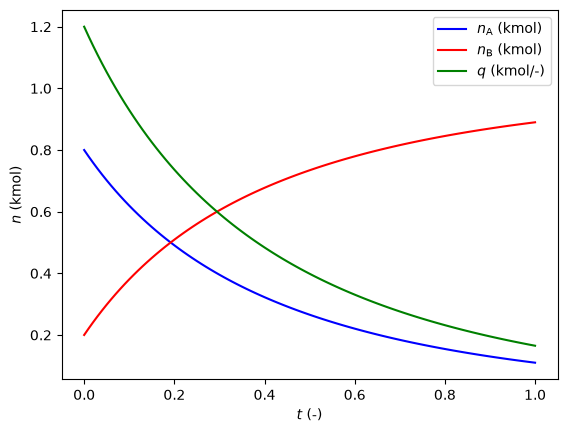

In [5]:
import numpy as np
import matplotlib.pyplot as plt

print("x:", r.x.shape, "(points, states)")
print("max |n_A - exact| along the trajectory: %.2e"
      % np.abs(r.x[:, 0] - a*np.exp(-K*r.t)/(1. - a*np.exp(-K*r.t)/NT)).max())
print("max |n_A + n_B - n_T|                 : %.2e" % np.abs(r.x[:, 0] + r.x[:, 1] - NT).max())

plt.xlabel('$t$ (-)')
plt.ylabel('$n$ (kmol)')
plt.plot(r.t, r.x[:, 0], "-b", label="$n_{\\sf A}$ (kmol)")
plt.plot(r.t, r.x[:, 1], "-r", label="$n_{\\sf B}$ (kmol)")
plt.plot(r.t, r.x[:, 2], "-g", label="$q$ (kmol/-)")
plt.legend(loc="best")
plt.show()

## Forward and adjoint sensitivities

Both outputs are differentiated with respect to both input parameters. `solve_fsens` carries one
sensitivity system per parameter alongside the states; `solve_asens` integrates the model forward
and the adjoints backward, one backward problem per output. The first costs one solve per parameter,
the second one per output -- so the choice between them is usually a matter of which is larger.

`val_function_gradient()` returns one row per parameter and one column per output, the same shape
from either route.

In [6]:
IVP.solve_fsens({k: [K], nA0: [NA0], nT: [NT]})
Gf = np.array(IVP.val_function_gradient())

IVP.solve_asens({k: [K], nA0: [NA0], nT: [NT]})
Ga = np.array(IVP.val_function_gradient())

print("forward  d[n_A(1), vented] / d[k, nA0]:\n", Gf)
print("adjoint:\n", Ga)
print("max |forward - adjoint| = %.2e" % np.abs(Gf - Ga).max())

forward  d[n_A(1), vented] / d[k, nA0]:
 [[-0.12220503  0.11008608]
 [ 0.0848646   0.47910689]]
adjoint:
 [[-0.12220502  0.11008608]
 [ 0.0848646   0.47910689]]
max |forward - adjoint| = 9.54e-09


The sensitivity of $n_{\sf A}(1)$ to $n_{\sf A}(0)$ can be checked in closed form as well:
$\frac{\partial n_{\sf A}(1)}{\partial n_{\sf A}(0)} = \frac{\partial}{\partial n_{\sf A}(0)}
\frac{a e^{-k}}{1 - a e^{-k}/n^\ast}$ with $a = n_{\sf A}(0)/(1 + n_{\sf A}(0)/n^\ast)$.

In [7]:
e = math.exp(-K)
da_dn0 = 1./(1. + NA0/NT)**2                      # da/d n_A(0)
dnA_da = e/(1. - a*e/NT)**2                       # d n_A(1)/da
print("d n_A(1)/d n_A(0): forward %.8f   adjoint %.8f   closed form %.8f"
      % (Gf[1, 0], Ga[1, 0], da_dn0*dnA_da))

d n_A(1)/d n_A(0): forward 0.08486460   adjoint 0.08486460   closed form 0.08486460


The sensitivity trajectories themselves are recorded too, one per parameter, in the same shape
`ODESLV` records them.

xp: (2, 101, 3) (directions, points, states)


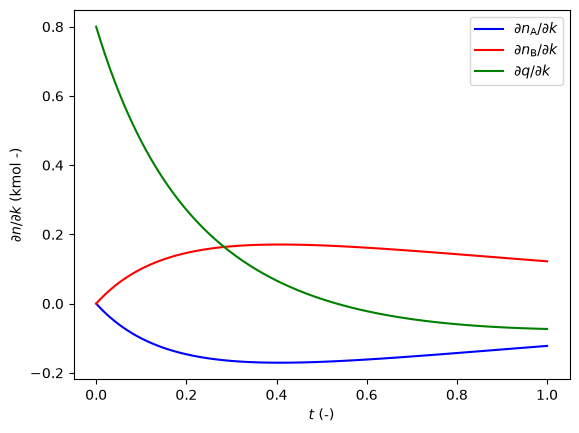

In [8]:
IVP.solve_fsens({k: [K], nA0: [NA0], nT: [NT]})
sens = IVP.results_fsens
ik = IVP.parameter_index(k)[0]
print("xp:", sens.xp.shape, "(directions, points, states)")

plt.xlabel('$t$ (-)')
plt.ylabel(r'$\partial n / \partial k$ (kmol -)')
plt.plot(sens.t, sens.xp[ik, :, 0], "-b", label=r"$\partial n_{\sf A}/\partial k$")
plt.plot(sens.t, sens.xp[ik, :, 1], "-r", label=r"$\partial n_{\sf B}/\partial k$")
plt.plot(sens.t, sens.xp[ik, :, 2], "-g", label=r"$\partial q/\partial k$")
plt.legend(loc="best")
plt.show()

And the adjoint trajectories, in increasing time. The multiplier of the algebraic equation --
$\lambda_q$ -- is the one the terminal condition cannot get from $J_{y'}^\mathsf{T}\lambda(T) =
\partial f/\partial x$ alone, and that consistent initialisation supplies.

l: (2, 102, 3) (outputs, points, states)


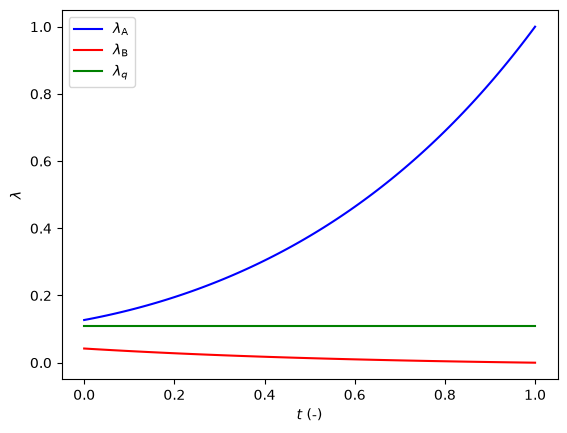

In [9]:
IVP.solve_asens({k: [K], nA0: [NA0], nT: [NT]})
adj = IVP.results_asens
iF = 0                                       # the first output, n_A(1)
print("l:", adj.l.shape, "(outputs, points, states)")

plt.xlabel('$t$ (-)')
plt.ylabel(r'$\lambda$')
plt.plot(adj.t, adj.l[iF, :, 0], "-b", label=r"$\lambda_{\sf A}$")
plt.plot(adj.t, adj.l[iF, :, 1], "-r", label=r"$\lambda_{\sf B}$")
plt.plot(adj.t, adj.l[iF, :, 2], "-g", label=r"$\lambda_q$")
plt.legend(loc="best")
plt.show()

## The solver as a DAG operation

`FFDAESLV` embeds the solver in the DAG as an external operation, so the simulation becomes a
function of DAG variables that can be composed with others, evaluated, and differentiated. It is the
same template as `FFODESLV`, instantiated on `DAESLV`.

Here the two parameters are mapped onto fresh DAG variables `P_k` and `P_n`, and the outputs come
back as DAG variables.

In [10]:
#P_k, P_n = DAG.add_var("P_k"), DAG.add_var("P_n")
OpDAE = FFDAESLV()
Y = OpDAE({k: [k], nA0: [nA0]}, {nT: [nT]}, IVP)
print("the operation:", OpDAE.name(), " ->", len(Y), "output variables")

val = DAG.eval(Y, [k, nA0, nT], [K, NA0, NT])
print("evaluated through the DAG: n_A(1) = %.10f, vented = %.10f" % (val[0], val[1]))

the operation: DAE[0x116632b0]  -> 2 output variables
evaluated through the DAG: n_A(1) = 0.1100860818, vented = 0.4833491008


FFModel::setup ** high-index reduction: 1 hidden constraint level(s) materialised at the initial point (block 0); the model declares the free initial data only


FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3


Because it is a DAG operation, it differentiates like any other: the derivative is taken by the
DAG, and the solver supplies its own sensitivities underneath. `fdiff` returns the Jacobian in
sparse triplet form: the row and column of each entry, and the DAG variable holding it.

In [11]:
rows, cols, dY = DAG.fdiff(Y, [k, nA0])
der = DAG.eval(dY, [k, nA0, nT], [K, NA0, NT])

J = np.zeros((len(Y), 2))
for i, j, v in zip(rows, cols, der):
    J[i, j] = v

print("d[outputs]/d[k, nA0] through the DAG:\n", J)
print("max difference from solve_fsens: %.2e" % np.abs(J - Gf.T).max())

d[outputs]/d[k, nA0] through the DAG:
 [[-0.12220503  0.0848646 ]
 [ 0.11008608  0.47910689]]
max difference from solve_fsens: 0.00e+00
FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3


FFModel::setup ** high-index reduction: 1 hidden constraint level(s) materialised at the initial point (block 0); the model declares the free initial data only


## Parallel scenario evaluation

A DAG operation can be sampled over many inputs at once. `veval` evaluates the subgraph for every
row of a sample, spreading the work over threads -- each thread holding its own copy of the solver,
which is why the solver keeps its model on a private DAG.

Here we sweep the rate constant and the initial charge over a grid of operating scenarios and look at
how much gas each one vents.

In [12]:
from scipy.stats import qmc

sampler = qmc.Sobol(d=2, scramble=False, seed=1)
samInput = sampler.random_base2(m=12)  # 2^12 ~ 4,096 evaluations
samInput[:, 0] = 0.5 + samInput[:, 0] * (3.0 - 0.5)
samInput[:, 1] = 0.4 + samInput[:, 1] * (0.95 - 0.4)

print(samInput)

[[0.5        0.4       ]
 [1.75       0.675     ]
 [2.375      0.5375    ]
 ...
 [2.37561035 0.78013916]
 [1.75061035 0.64263916]
 [0.50061035 0.91763916]]


In [13]:
DAG.options.MAXTHREAD = 0                    # use every available thread

samOutput = DAG.veval(Y, [k, nA0], samInput.tolist(), [nT], [NT], walltime=True)
print(np.array(samOutput))

FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3
[[0.20962056 0.14616551]
 [0.07530154 0.44321204]
 [0.03361017 0.39710003]
 ...
 [0.04246847 0.53510011]
 [0.07289573 0.42594291]
 [0.40857622 0.3085154 ]]
FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3
FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3
FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3
FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3
FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3
FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns=4 states=3
FFModel::setup [classify] block 0: DIFFERENTIAL_ALGEBRAIC  evolution coefficient singular  eqns

FFModel::setup ** high-index reduction: 1 hidden constraint level(s) materialised at the initial point (block 0); the model declares the free initial data only
vectorized DAG evaluation on 0 threads: 0.478583 sec
FFModel::setup ** high-index reduction: 1 hidden constraint level(s) materialised at the initial point (block 0); the model declares the free initial data only
FFModel::setup ** high-index reduction: 1 hidden constraint level(s) materialised at the initial point (block 0); the model declares the free initial data only
FFModel::setup ** high-index reduction: 1 hidden constraint level(s) materialised at the initial point (block 0); the model declares the free initial data only
FFModel::setup ** high-index reduction: 1 hidden constraint level(s) materialised at the initial point (block 0); the model declares the free initial data only
FFModel::setup ** high-index reduction: 1 hidden constraint level(s) materialised at the initial point (block 0); the model declares the free initi

Venting is what holds the pressure down, so more gas leaves the vessel the further the reaction
proceeds -- and since each mole of ${\sf A}$ becomes two of ${\sf B}$, the vented amount approaches
the initial charge as $k$ grows and the reaction runs to completion within the batch.

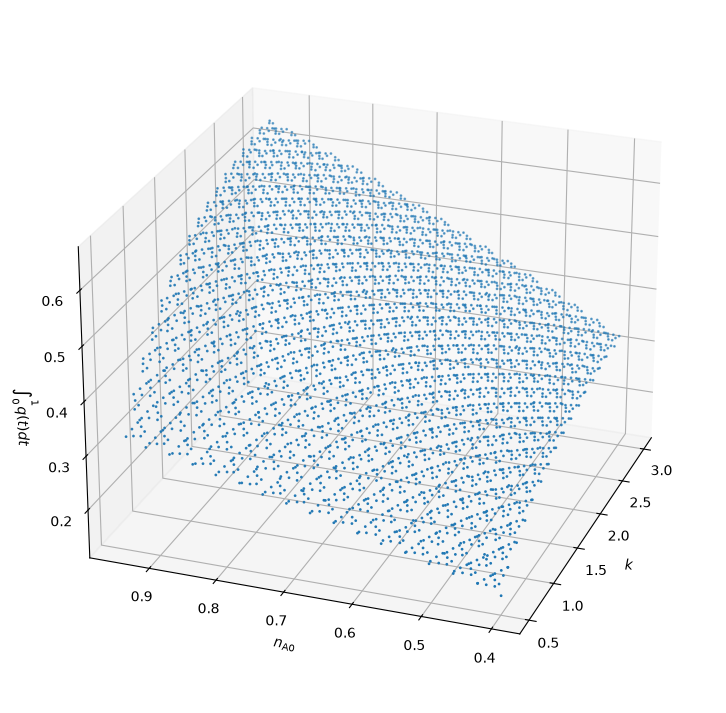

In [14]:
samOutput = np.array(samOutput)

fig = plt.figure(figsize=(14, 9))
ax = plt.axes(projection='3d')
ax.set_xlabel(r"$k$")
ax.set_ylabel(r"$n_{{\sf A}0}$")
ax.set_zlabel(r"$\int_0^1 q(t) dt$")

ax.scatter(samInput[:, 0], samInput[:, 1], samOutput[:, 1], s=1)
ax.view_init(elev=25, azim=200)

plt.show()